In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/content/drive/MyDrive/ML/iris-write-from-docker.csv')
print("Shape:", df.shape)
print(df.head(10))

Shape: (150, 5)
   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
5           5.4          3.9           1.7          0.4  Iris-setosa
6           4.6          3.4           1.4          0.3  Iris-setosa
7           5.0          3.4           1.5          0.2  Iris-setosa
8           4.4          2.9           1.4          0.2  Iris-setosa
9           4.9          3.1           1.5          0.1  Iris-setosa


In [15]:
feature_cols = [col for col in df.columns if col != 'class']
target_col ="class"

x = df[feature_cols].to_numpy(dtype=float)
y = df[target_col]

print(x.shape,y.shape)

(150, 4) (150,)


In [16]:
unique_classes = np.unique(y)#
class_0 = unique_classes[0]
class_1 = unique_classes[1]
target_names=[class_0,class_1]
mask = (y== class_0) | (y == class_1)

X = x[mask]
y_filtered = y[mask]

print(class_0,class_1)


Iris-setosa Iris-versicolor


In [17]:
print(df['class'][:5])
print(target_names)#original targets in project

0    Iris-setosa
1    Iris-setosa
2    Iris-setosa
3    Iris-setosa
4    Iris-setosa
Name: class, dtype: object
['Iris-setosa', 'Iris-versicolor']


In [61]:
y_svm = np.where(y==class_0, -1, 1) # I choose class_0 as check point here
print("svm targets: ", np.unique(y_svm))

svm targets:  [-1  1]


In [60]:
def train_test_split_numpy(x,y,test_size=0.2,seed=42):
  rng = np.random.default_rng(seed)
  n_samples = x.shape[0]
  indices = np.arange(n_samples)
  rng.shuffle(indices)
  test_count = int(n_samples * test_size) # 20% of data for test
  test_indices = indices[:test_count]
  train_indices = indices[test_count:]

  x_train = x[train_indices]
  y_train = y[train_indices]
  x_test = x[test_indices]
  y_test = y[test_indices]

  return x_train, x_test, y_train, y_test

x_train, x_test, y_train, y_test = train_test_split_numpy(x,y_svm,test_size=0.2,seed=42)

print("x train shape:",x_train.shape,"\nx test shape:", x_test.shape, "\ny train shape:",y_train.shape, "\ny test shape:",y_test.shape)

x train shape: (120, 4) 
x test shape: (30, 4) 
y train shape: (120,) 
y test shape: (30,)


In [27]:
#STANDARDIZATION
train_mean= x_train.mean(axis=0)
train_std = x_train.std(axis=0)
train_std=np.where(train_std==0,1,train_std)


x_train = (x_train - train_mean) / train_std
x_test = (x_test - train_mean) / train_std

print(x_train[:3])# 3 rows of standarized xtrain

[[-0.27026963 -0.80343997  0.26748398  0.12152547]
 [ 0.58001686  0.55768186  0.5535631   0.51566215]
 [-0.14880014 -0.34973269  0.26748398  0.12152547]]


In [33]:
#hinge loss implementation (-1,+1 classification :p)
def svm_hinge_loss(x,y,w,b, lambda_param):
  distances= 1-y * (x @ w + b)
  distances= np.maximum(0, distances)

  hinge_loss= np.mean(distances)
  regularization= lambda_param * np.sum(w ** 2)

  return hinge_loss + regularization

In [36]:
def train_linear_svm(x, y, lr=0.001, lambda_param=0.01, epochs=1000):
  n_samples, n_features = x.shape

  w = np.zeros(n_features)
  b = 0.0

  loss_history = []
  for epoch in range(epochs):
      for i in range(n_samples):
          condition = y[i] * (np.dot(x[i], w) + b) >= 1

          if condition:
              dw = 2 * lambda_param * w
              db = 0.0
          else:
              dw = 2 * lambda_param * w - y[i] * x[i]
              db = -y[i]

          w -= lr * dw
          b -= lr * db
      loss= svm_hinge_loss(x,y,w,b,lambda_param)
      loss_history.append(loss)

      if (epoch + 1) % 100 == 0 or epoch == 0:
        print(f"epoch {epoch +1}/{epochs}, loss: {loss:.5f}")

  return w,b,loss_history

In [37]:
w,b,loss_history = train_linear_svm(x_train,y_train,lr=0.001,lambda_param=0.01,epochs=1000)

epoch 1/1000, loss: 0.72309
epoch 100/1000, loss: 0.01837
epoch 200/1000, loss: 0.01782
epoch 300/1000, loss: 0.01781
epoch 400/1000, loss: 0.01778
epoch 500/1000, loss: 0.01778
epoch 600/1000, loss: 0.01777
epoch 700/1000, loss: 0.01777
epoch 800/1000, loss: 0.01778
epoch 900/1000, loss: 0.01777
epoch 1000/1000, loss: 0.01778


In [38]:
def predict_svm(x,w,b):
  scores = x @ w + b
  return np.where(scores >= 0, 1, -1)

In [39]:
y_pred = predict_svm(x_test,w,b)

In [40]:
def accuracy_score(y_true, y_pred):
    return np.mean(y_true == y_pred)

In [42]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy) #wow result is excellent

Accuracy: 1.0


epoch 1/1000, loss: 0.89673
epoch 100/1000, loss: 0.08630
epoch 200/1000, loss: 0.08076
epoch 300/1000, loss: 0.07967
epoch 400/1000, loss: 0.07946
epoch 500/1000, loss: 0.07933
epoch 600/1000, loss: 0.07926
epoch 700/1000, loss: 0.07920
epoch 800/1000, loss: 0.07920
epoch 900/1000, loss: 0.07921
epoch 1000/1000, loss: 0.07921


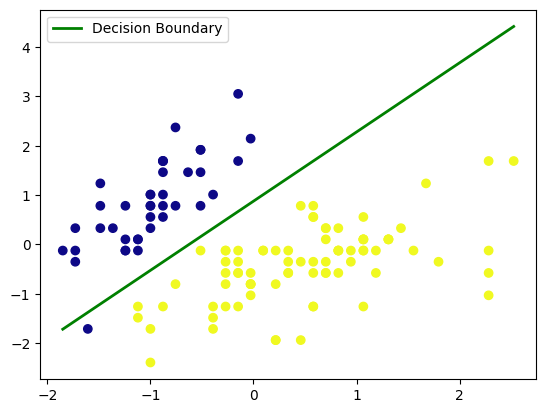

In [59]:
# for visulazion I guess I must take only 2 features for 2D visualization,so I retrained the model
# because we cannot plot a 4D decision boundary on a 2D screen
x_train_new = x_train[:, :2]
w_new, b_new, _ = train_linear_svm(x_train_new, y_train, lr=0.001, lambda_param=0.01, epochs=1000)

plt.scatter(x_train_new[:, 0], x_train_new[:, 1], c= y_train, cmap='plasma')# 'c=y_train' assigns colors based on the target class (-1 or 1)

# for plot decision boundary (green line)
x_cizgi = np.array([min(x_train_new[:, 0]), max(x_train_new[:, 0])])
y_cizgi = -(w_new[0] * x_cizgi + b_new) / w_new[1]

plt.plot(x_cizgi, y_cizgi, color='green', linewidth=2, label='Decision Boundary')
plt.legend()
plt.show()

In [62]:
'''
In 4D, those two groups are completely separate(accurracy is 1.0).
 But to see the data on a flat 2D graph, I trained the model again using only two features: the length and width of the sepal.
 In this limited 2D space, the data points cannot perfectly separated by a straight line.
'''

'\nIn 4D, those two groups are completely separate(accurracy is 1.0).\n But to see the data on a flat 2D graph, I trained the model again using only two features: the length and width of the sepal. \n In this limited 2D space, the data points cannot perfectly separated by a straight line.\n'